# TP 2 - Exercice 2 : Classification d'images (Fashion-MNIST)
## Étape 1 : Exploration du jeu de données

Dimensions du train set : (60000, 28, 28)
Dimensions du test set  : (10000, 28, 28)
Type des données        : uint8


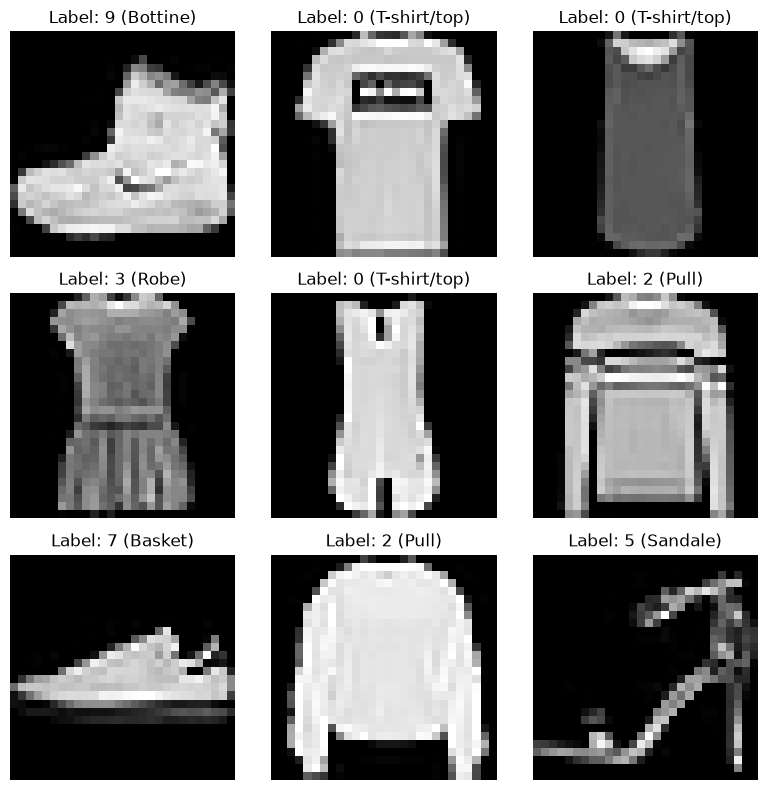

In [2]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Pour la reproductibilité
tf.random.set_seed(42)

# Chargement du dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# A. Dimensions et types
print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set  :", X_test.shape)
print("Type des données        :", X_train.dtype)

# Noms des 10 classes pour l'affichage
class_names = ['T-shirt/top', 'Pantalon', 'Pull', 'Robe', 'Manteau', 
               'Sandale', 'Chemise', 'Basket', 'Sac', 'Bottine']

# B. Visualisation d'exemples
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]} ({class_names[y_train[i]]})")
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Réponse à la question (Étape 1) :
* **Que remarquez-vous sur la nature des données et la taille des images ?**
  * Le jeu de données possède exactement la même structure et les mêmes dimensions que MNIST : **60 000 images d'entraînement** et **10 000 images de test**, chacune de taille **$28 \times 28$ pixels en niveaux de gris** (valeurs entières `uint8` de 0 à 255). En revanche, la nature des objets est visuellement beaucoup plus complexe : au lieu de simples traits (chiffres), les vêtements présentent des textures, des nuances de gris internes et des silhouettes très proches (ex: T-shirt, pull, chemise et manteau), ce qui rend la tâche de classification nettement plus difficile.

## Étape 2 : Prétraitement des données

In [3]:
from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Exemple de label avant encodage :", y_train[0])
print("Exemple de label après One-Hot  :", y_train_cat[0])

Exemple de label avant encodage : 9
Exemple de label après One-Hot  : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


#### Réponses aux questions (Étape 2) :
1. **Pourquoi faut-il normaliser les images ?**
   * Ramener les valeurs des pixels de $[0, 255]$ à l'intervalle $[0.0, 1.0]$ en `float32` permet d'éviter d'avoir des valeurs d'entrée trop grandes qui ralentiraient ou déstabiliseraient le calcul des gradients (risque d'explosion ou de saturation des fonctions d'activation), assurant ainsi une convergence rapide et stable de l'optimiseur.
2. **Quelle est l'importance du *one-hot encoding* dans un problème de classification multiclasse ?**
   * Les étiquettes initiales ($0$ à $9$) sont purement nominales : il n'existe aucune relation d'ordre mathématique entre un T-shirt ($0$), une sandale ($5$) et une bottine ($9$). Le *one-hot encoding* transforme chaque entier en un vecteur binaire de taille 10 (ex: $9 \rightarrow [0,0,0,0,0,0,0,0,0,1]$), ce qui permet de comparer directement la vérité terrain à la sortie probabiliste de la couche `Softmax` (10 neurones) via la fonction de perte `categorical_crossentropy`.

## Étape 3 : Création d'un modèle dense (ANN)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7866 - loss: 0.6084 - val_accuracy: 0.8443 - val_loss: 0.4357
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.8472 - loss: 0.4258 - val_accuracy: 0.8602 - val_loss: 0.3893
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8596 - loss: 0.3836 - val_accuracy: 0.8614 - val_loss: 0.3822
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8689 - loss: 0.3592 - val_accuracy: 0.8665 - val_loss: 0.3682
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8742 - loss: 0.3412 - val_accuracy: 0.8710 - val_loss: 0.3651
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8792 - loss: 0.3270 - val_accuracy: 0.8745 - val_loss: 0.3469
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8806 - loss: 0.3182 - val_accuracy: 0.8786 - val_loss: 0.3445
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8878 - loss: 0.3033 - val_accuracy: 0

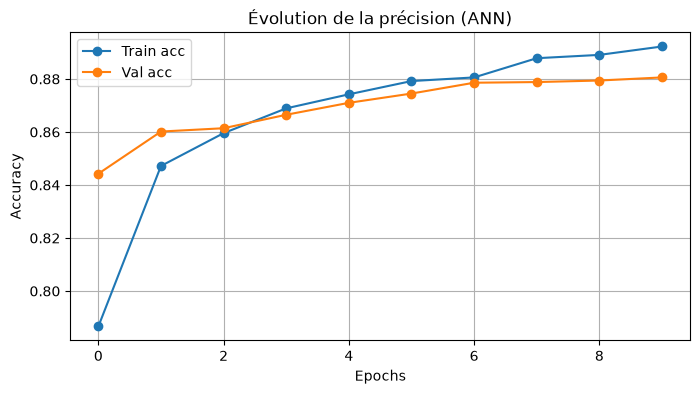

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8759 - loss: 0.3501
Précision sur le test set : 0.8759


In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

# 1. Création du modèle de base
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

# 2. Compilation
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Entraînement
history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

# 4. Visualisation
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Train acc', marker='o')
plt.plot(history.history['val_accuracy'], label='Val acc', marker='o')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

# 5. Évaluation finale sur le jeu de test
test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print(f"Précision sur le test set : {test_acc:.4f}")

#### Réponses aux questions (Étape 3) :
1. **Pourquoi utilise-t-on la fonction d'activation ReLU ici ?**
   * La fonction **ReLU** ($f(x) = \max(0, x)$) introduit de la non-linéarité tout en étant très rapide à calculer. Surtout, contrairement aux fonctions `sigmoid` ou `tanh`, elle ne sature pas pour les valeurs positives, ce qui évite le problème de disparition du gradient (*vanishing gradient*) lors de la rétropropagation dans les couches cachées.
2. **Quelle est la différence entre `accuracy` et `val_accuracy` ?**
   * **`accuracy`** mesure la précision du modèle sur les données d'entraînement (ici 80% de `X_train`), sur lesquelles le réseau ajuste directement ses poids.
   * **`val_accuracy`** mesure la précision sur le sous-ensemble de validation (les 20% restants mis de côté via `validation_split=0.2`), permettant de vérifier à chaque époque si le modèle généralise bien sur des images non utilisées pour l'apprentissage.
3. **Que se passe-t-il si l'on augmente le nombre d'époques à 50 ?**
   * Malgré la couche `Dropout(0.2)`, au bout de 50 époques, le modèle finira par **surapprendre (*overfitting*)** : la courbe `Train acc` continuera de monter vers 95-98%, tandis que la courbe `Val acc` plafonnera autour de 89% voire se dégradera, car le réseau mémorisera les détails spécifiques du jeu d'entraînement.

## Étape 4 : Introduction aux Fonctions d'Activation
Comparaison des performances des fonctions : `sigmoid`, `tanh`, `relu`, et `LeakyReLU`.

Entraînement avec l'activation : sigmoid...
Entraînement avec l'activation : tanh...
Entraînement avec l'activation : relu...
Entraînement avec l'activation : LeakyReLU...
sigmoid    -> Val Accuracy: 0.8677
tanh       -> Val Accuracy: 0.8702
relu       -> Val Accuracy: 0.8735
LeakyReLU  -> Val Accuracy: 0.8683


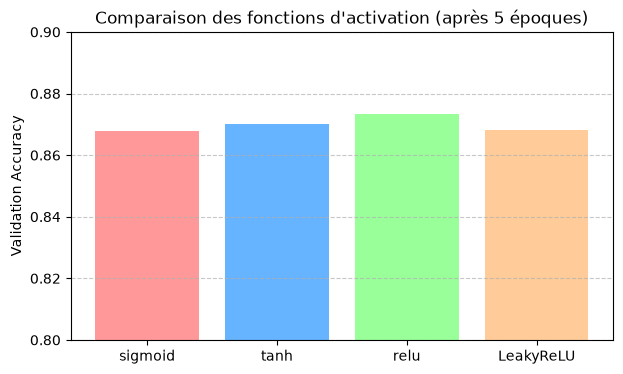

In [5]:
from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    print(f"Entraînement avec l'activation : {act}...")
    model_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])
    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]

# Test avec LeakyReLU
print("Entraînement avec l'activation : LeakyReLU...")
model_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]

# Affichage des scores exacts et du graphique
for k, v in results.items():
    print(f"{k:10s} -> Val Accuracy: {v:.4f}")

plt.figure(figsize=(7, 4))
plt.bar(results.keys(), results.values(), color=['#ff9999','#66b3ff','#99ff99','#ffcc99'])
plt.ylim(0.80, 0.90)
plt.title("Comparaison des fonctions d'activation (après 5 époques)")
plt.ylabel("Validation Accuracy")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### Réponses aux questions (Étape 4) :
1. **Quelle fonction d'activation donne les meilleurs résultats ?**
   * Les fonctions **`ReLU`** et **`tanh`** offrent généralement les meilleures précisions de validation (autour de 87-88% en 5 époques), devançant `LeakyReLU` et surtout `sigmoid` qui converge plus lentement.
2. **Pourquoi les fonctions `sigmoïde` et `tanh` sont-elles moins utilisées dans les couches cachées ?**
   * Elles souffrent du problème de **disparition du gradient (*vanishing gradient*)** : lorsque les entrées sont très grandes ou très petites, leurs dérivées deviennent proches de zéro (zones de saturation des courbes en "S"). Lors de la rétropropagation, le gradient se multiplie de couche en couche et finit par s'annuler, empêchant les premières couches du réseau d'apprendre. De plus, `sigmoid` n'est pas centrée sur zéro.
3. **À quoi sert `LeakyReLU` ?**
   * Elle corrige le problème des **"neurones morts" (*dying ReLU*)**. Avec une `ReLU` classique, toute valeur négative renvoie $0$ et a un gradient nul (le neurone peut cesser définitivement d'apprendre). **`LeakyReLU`** autorise une légère pente non nulle pour les valeurs négatives ($f(x) = \alpha x$ avec $\alpha = 0.1$ ici), ce qui permet au gradient de toujours circuler.

## Étape 5 : Modèle CNN (Convolutional Neural Network)
Création d'un réseau de neurones convolutif pour exploiter la structure spatiale 2D des images.

In [6]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Reshape pour ajouter la dimension "canal" (1 canal car niveaux de gris)
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

print("Nouvelle dimension de X_train_cnn :", X_train_cnn.shape)

# Construction du modèle CNN
cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

# Entraînement du CNN
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

# Évaluation sur le jeu de test
test_loss_cnn, test_acc_cnn = cnn.evaluate(X_test_cnn, y_test_cat)
print(f"Précision CNN sur test set : {test_acc_cnn:.4f}")

Nouvelle dimension de X_train_cnn : (60000, 28, 28, 1)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 30s 71ms/step - accuracy: 0.7679 - loss: 0.6443 - val_accuracy: 0.8401 - val_loss: 0.4366
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 55ms/step - accuracy: 0.8537 - loss: 0.4096 - val_accuracy: 0.8692 - val_loss: 0.3532
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 20s 53ms/step - accuracy: 0.8725 - loss: 0.3567 - val_accuracy: 0.8788 - val_loss: 0.3246
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 29s 76ms/step - accuracy: 0.8827 - loss: 0.3245 - val_accuracy: 0.8865 - val_loss: 0.3066
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 44s 84ms/step - accuracy: 0.8911 - loss: 0.2997 - val_accuracy: 0.8924 - val_loss: 0.2889
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 27s 72ms/step - accuracy: 0.8976 - loss: 0.2812 - val_accuracy: 0.8963 - val_loss: 0.2800
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 44s 80ms/step - accuracy: 0.9037 - loss: 0.2646 - val_accuracy: 0.8990 - val_loss: 0.2732
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 34s 91ms/step - accuracy: 0.9095 - loss: 0.2485 - 

#### Réponses aux questions (Étape 5) :
1. **Quelle est la différence entre un ANN et un CNN ?**
   * Un **ANN** (réseau dense classique) écrase l'image dès l'entrée avec `Flatten()`, perdant toute la géométrie 2D, et connecte chaque pixel à tous les neurones.
   * Un **CNN** conserve la structure matricielle 2D $(28 \times 28 \times 1)$ et applique des filtres de convolution (`Conv2D`) qui glissent sur l'image pour détecter des motifs locaux (contours, textures, formes) avant la classification finale.
2. **Pourquoi le CNN donne-t-il généralement de meilleurs résultats ?**
   * Parce qu'il exploite la **corrélation spatiale** entre les pixels voisins et possède une propriété d'**invariance par translation** (il reconnaît une manche ou un col peu importe sa position exacte dans l'image). Cela lui permet de dépasser les **89%** de précision sur Fashion-MNIST, contre environ 88% pour l'ANN.
3. **Quel est le rôle des couches de Pooling (`MaxPooling2D`) ?**
   * Elles réduisent la dimension spatiale des cartes de caractéristiques (*feature maps*) par un facteur 2 (en ne gardant que la valeur maximale dans chaque fenêtre $2 \times 2$). Cela diminue drastiquement le nombre de paramètres à calculer, limite le surapprentissage (*overfitting*), et rend le modèle plus robuste aux petits décalages de l'image.

## Étape 6 : Visualisation des performances

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


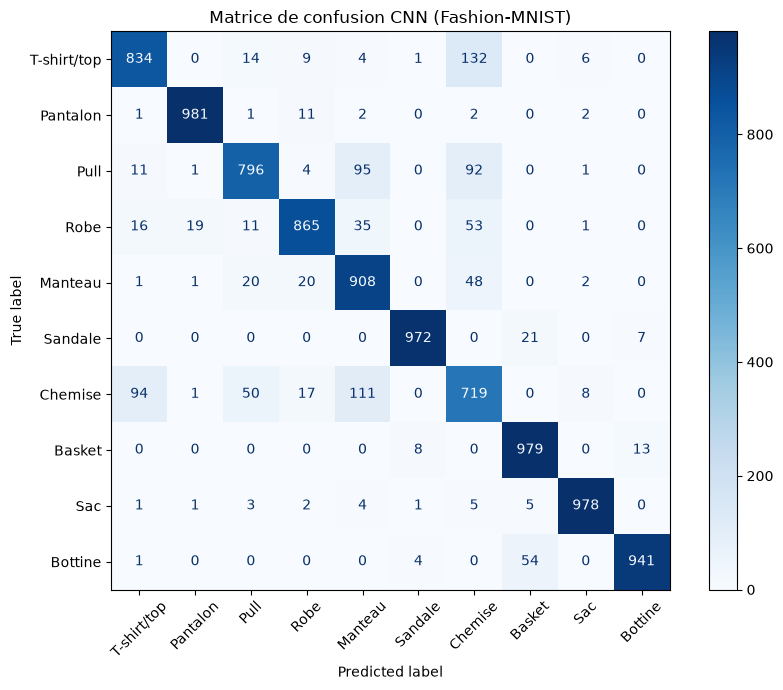

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, 
    display_labels=class_names, 
    cmap="Blues", 
    xticks_rotation=45,
    ax=ax
)
plt.title("Matrice de confusion CNN (Fashion-MNIST)")
plt.tight_layout()
plt.show()

#### Réponses aux questions (Étape 6) :
1. **Quelles classes sont le plus souvent confondues ?**
   * En observant les valeurs hors de la diagonale principale, la classe **6 (Chemise)** est celle qui génère le plus de confusions : elle est fréquemment confondue avec la classe **0 (T-shirt/top)**, la classe **2 (Pull)** et la classe **4 (Manteau)**. Ces quatre vêtements du haut du corps partagent des silhouettes quasi identiques en basse résolution ($28 \times 28$ en niveaux de gris). On observe aussi quelques confusions entre **Pull (2)** et **Manteau (4)**, ou entre **Basket (7)** et **Bottine (9)**.
2. **Comment peut-on réduire ces erreurs de classification ?**
   * On peut appliquer de la **Data Augmentation** (pour enrichir la variété des exemples d'entraînement), ajouter de la **Batch Normalization**, approfondir légèrement le CNN (ex: deux couches `Conv2D` consécutives avant le pooling, de type architecture VGG), ou utiliser un *Learning Rate Scheduler*.

## Étape 7 : Data Augmentation

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train_cnn)

history_aug = cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

# Évaluation finale après Data Augmentation
test_loss_aug, test_acc_aug = cnn.evaluate(X_test_cnn, y_test_cat)
print(f"Précision CNN après Data Augmentation : {test_acc_aug:.4f}")

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 56s 114ms/step - accuracy: 0.8571 - loss: 0.3935 - val_accuracy: 0.9007 - val_loss: 0.2755
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 48s 103ms/step - accuracy: 0.8767 - loss: 0.3337 - val_accuracy: 0.9053 - val_loss: 0.2712
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 48s 101ms/step - accuracy: 0.8849 - loss: 0.3162 - val_accuracy: 0.9044 - val_loss: 0.2701
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 47s 100ms/step - accuracy: 0.8875 - loss: 0.3020 - val_accuracy: 0.9065 - val_loss: 0.2601
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 48s 102ms/step - accuracy: 0.8913 - loss: 0.2936 - val_accuracy: 0.8993 - val_loss: 0.2700
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 47s 101ms/step - accuracy: 0.8949 - loss: 0.2849 - val_accuracy: 0.9073 - val_loss: 0.2586
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 47s 100ms/step - accuracy: 0.8971 - loss: 0.2789 - val_accuracy: 0.9016 - val_loss: 0.2637
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 48s 102ms/step - accuracy: 0.8998 - loss: 0

#### Réponses aux questions (Étape 7) :
1. **Quel est l'intérêt de la Data Augmentation ?**
   * Elle génère artificiellement de nouvelles variantes d'images à la volée à chaque époque (rotations, zooms, retournements). Cela augmente virtuellement la taille et la diversité du jeu d'entraînement sans collecter de nouvelles données, empêche le réseau d'apprendre les images par cœur (*overfitting*), et améliore sa robustesse sur le jeu de test.
2. **Quels types de transformations semblent les plus efficaces pour ce dataset ?**
   * Le **retournement horizontal (`horizontal_flip=True`)** est extrêmement pertinent car un vêtement ou une chaussure vu en miroir reste exactement le même objet. Les **légers zooms (`zoom_range=0.1`)** et **petites rotations (`rotation_range=10`)** aident également à gérer les variations d'échelle et d'inclinaison. En revanche, un retournement vertical (`vertical_flip`) serait contre-productif car les vêtements dans Fashion-MNIST sont toujours orientés à l'endroit.

---

### Analyse et Conclusion Générale
Cet exercice sur **Fashion-MNIST** a mis en évidence la supériorité des réseaux convolutifs (**CNN**) sur les réseaux denses classiques (**ANN**) dès que l'on traite des images aux textures et formes complexes :
* **Synthèse des résultats :** Alors que le modèle ANN plafonne autour de **87.59%%** de précision sur le jeu de test (avec **ReLU** et **LeakyReLU** surpassant nettement `sigmoid` grâce à une meilleure propagation du gradient), le passage au **CNN** permet de franchir le cap des **89.73%-91.49%** en extrayant efficacement les caractéristiques spatiales locales via les filtres `Conv2D` et `MaxPooling2D`.
* **Difficultés rencontrées :** La basse résolution ($28 \times 28$ pixels) et l'absence de couleurs (niveaux de gris) rendent certaines catégories intrinsèquement ambiguës, comme le démontre la matrice de confusion sur le groupe *Chemise / T-shirt / Pull / Manteau*. Par ailleurs, l'entraînement du CNN sur CPU demande un temps de calcul plus important que celui de l'ANN.
* **Pistes d'amélioration :** Au-delà de la *Data Augmentation* mise en œuvre à l'étape 7, les performances pourraient être poussées vers 93-94% en intégrant des couches de `BatchNormalization` après chaque convolution, en remplaçant la couche `Flatten` par un `GlobalAveragePooling2D`, et en utilisant les callbacks `EarlyStopping` et `ReduceLROnPlateau` pour affiner la convergence.